In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [3]:
# Load dataset
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')

In [4]:
# Select numerical columns
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']]

In [5]:
# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [6]:
# Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

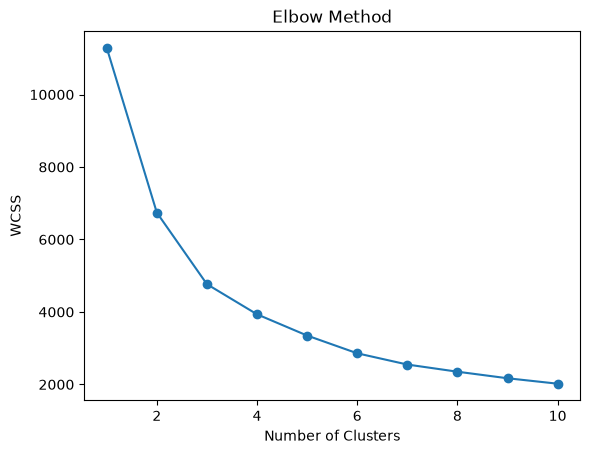

In [7]:
# Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [8]:
# Apply K-Means (choose 3 clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

In [9]:
# Display results
print(df[['SALES', 'QUANTITYORDERED', 'Cluster']].head(10))
print("\nCluster Counts:")
print(df['Cluster'].value_counts())

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1
5  3479.76               36        2
6  2497.77               29        2
7  5512.32               48        1
8  2168.54               22        2
9  4708.44               41        1

Cluster Counts:
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


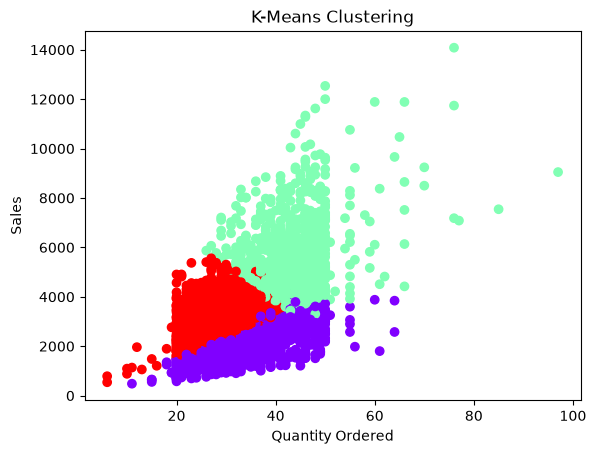

In [10]:
# Visualize Clusters
plt.scatter(df['QUANTITYORDERED'], df['SALES'],
            c=df['Cluster'], cmap='rainbow')
plt.xlabel('Quantity Ordered')
plt.ylabel('Sales')
plt.title('K-Means Clustering')
plt.show()